# Code for Task 3 : Figure 2
What is the relationship between the distance a shot was taken and the chance it was a goal? Produce a figure for each season between 2018-19 to 2020-21 to answer this, and add it to your blog post along with a couple of sentences describing your figure. Has there been much change over the past three seasons? Why did you choose this figure?

https://seaborn.pydata.org/generated/seaborn.kdeplot.html#seaborn.kdeplot 

In [ ]:
from ift6758.features import json2tidy

from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns

In [ ]:
#Copied from shot_style.ipynb
#List of the ids of each game
def games_ids(season):
    pathlist = Path(f"../notebooks/data/raw/{season}")
    return [p.stem for p in pathlist.glob("*.json")]

In [ ]:
#Copied from shot_style.ipynb
# Put all the dataframes in a list and merge them into one dataframe
def games_list(season,games_ids):
    df_games_list = []

    for game_id in games_ids:
        df = json2tidy(f"../notebooks/data/raw/{season}/{game_id}.json")
        df_games_list.append(df)

    merged_df_regular = pd.concat(df_games_list, ignore_index=True)
    return merged_df_regular

In [ ]:
def distance(year) -> pd.DataFrame:
    """
    Function to add the column distance to the dataframe.
    Distance is the distance between the goal and the coordinates where the shot was taken

    Parameters:
        year (int) : Year of the season

    Returns:
        pd.DataFrame
    """
    df = games_list(year,games_ids(year))

    #get the eventOwnerTeamId 
    team_id = df["team_id"]
    # if eventOwnerTeamId != hometeam_id then side_defending = homeTeamDefendingSide
    # else side_defending = inverse de homeTeamDefendingSide
    homeTeam_id = 54
    # True is home_team, False is away_team
    df["team_defending"] = (team_id == homeTeam_id)

    df["side_defending"] = df["homeTeamDefendingSide"]

    conditions = [df["side_defending"]=="right",df["side_defending"]=="left"]
    choices = ["left","right"]

    df["side_defending"] = np.where(df["team_defending"]==False,np.select(conditions,choices),df["side_defending"])
    
    # if right, goal_coor = (90,0)
    # else left, (-90,0)
    df["goalCoordX"] = np.where(df["side_defending"]=="right",90,-90)

    #calculate the distance between the x,y coordinates and the goal
    #the y coordinate for the goals is 0
    df["distance"] = np.sqrt((df["goalCoordX"]-df["x_coord"])**2 + df["y_coord"]**2)

    #Remove team_defending, side_defending, goalCoordX
    #Keep only the distance
    df = df.drop(
        columns = ["team_defending", "side_defending", "goalCoordX"]
    )

    return df


In [39]:
def figure2(season):
    """
    Function to draw kernel density estimate plot for the season specified

    Paramaters:
        season(int): Season to take de games from
    """
    df = distance(season)
    shot_or_goal = df[["distance","event_type"]] 

    shot = shot_or_goal[shot_or_goal["event_type"]=="shot-on-goal"]
    goal = shot_or_goal[shot_or_goal["event_type"]=="goal"]

    sns.kdeplot(shot["distance"])
    sns.kdeplot(goal["distance"])

c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


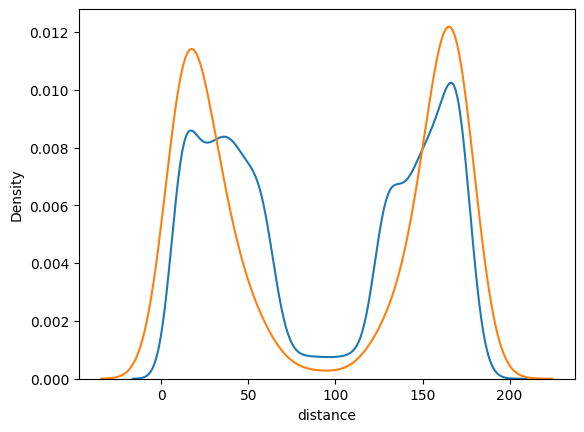

In [38]:
figure2(2018)

c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


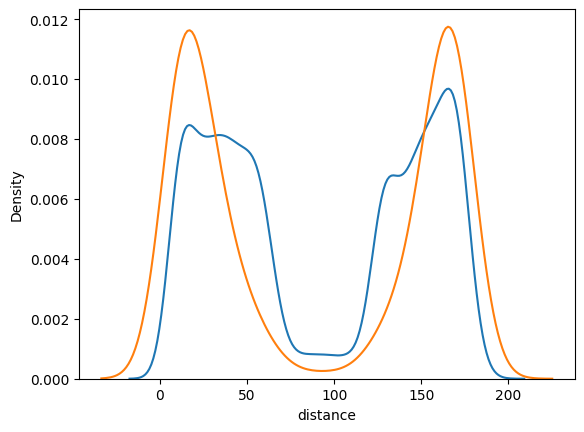

In [36]:
figure2(2019)

c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\tiffa\Desktop\IFT6758\Projet\NHL-data-analysis-main\NHL-data-analysis\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


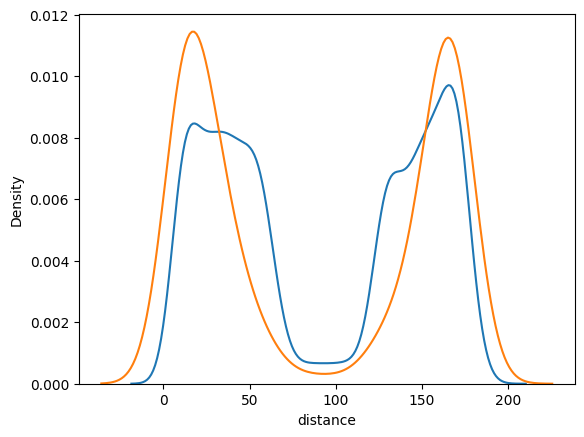

In [37]:
figure2(2020)